# From Degree to Employment: Early-Career Outcomes of Data and AI Graduates
## Milestone 2 – Getting, understanding and cleaning the data

**Group_13** 

**Group members:** Souchitra Vongsomphou · Hrayr Kostanyan · Paulo Alves de Oliveira Junior  · William Conlon

**Data:** National Survey of College Graduates (NSCG) 2023, Public Use File, National Center for Science and Engineering Statistics (NCSES/NSF): <https://ncses.nsf.gov/explore-data/microdata/national-survey-college-graduates>

Notebook outline:
1. Getting the data
2. Understanding the data
3. Cleaning and preprocessing (sample, reserved codes and missing data, target and class balance, unusual values, recoding, information leakage, feature scale)
4. The cleaned table
5. What we learned
6. Revised project question
7. Use of generative AI and outside resources (course policy)

In [1]:
from pathlib import Path
import zipfile

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt

import re, warnings

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)

In [2]:
URL = "https://ncses.nsf.gov/822/assets/0/files/college_grads_2023.zip"
DATA_DIR = Path("nscg_data")
ZIP_PATH = DATA_DIR / "college_grads_2023.zip"
CSV_NAME = "epcg23.csv"
SURVEY_YEAR = 2023            # reference week: February 2023

# chart styling: one blue for single-series charts, recessive axes
BLUE, ORANGE, INK2 = "#2a78d6", "#eb6834", "#52514e"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ae", "axes.labelcolor": INK2,
    "xtick.color": INK2, "ytick.color": INK2, "figure.dpi": 110,
})

def download(url=URL, dest=ZIP_PATH):
    dest.parent.mkdir(parents=True, exist_ok=True)
    if dest.exists():
        print(f"Already downloaded: {dest}")
        return dest
    print(f"Downloading {url} ...")
    headers = {"User-Agent": "Mozilla/5.0"}  # some government sites reject the default python UA
    with requests.get(url, headers=headers, stream=True, timeout=120) as r:
        r.raise_for_status()
        with open(dest, "wb") as f:
            for chunk in r.iter_content(chunk_size=1 << 20):
                f.write(chunk)
    return dest


def load(zip_path=ZIP_PATH):
    with zipfile.ZipFile(zip_path) as z:
        members = z.namelist()
        member = next(n for n in members if n.lower().endswith(CSV_NAME))
        csv_path = DATA_DIR / member
        if not csv_path.exists():
            z.extract(member, DATA_DIR)
    df = pd.read_csv(csv_path, dtype=str, low_memory=False)
    return df, csv_path, members


zip_path = download()
df, csv_path, zip_members = load(zip_path)

print("Files in the archive:")
for m in zip_members:
    print("   ", m)
print()
print(f"Zip archive (download):  {zip_path.stat().st_size / 1e6:8.1f} MB")
print(f"CSV on disk:             {csv_path.stat().st_size / 1e6:8.1f} MB")
print(f"DataFrame in memory:     {df.memory_usage(deep=True).sum() / 1e6:8.1f} MB")
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")

Already downloaded: nscg_data\college_grads_2023.zip
Files in the archive:
    pcg23Public/
    pcg23Public/2023-NSCG-21_annotated_7Aug25.pdf
    pcg23Public/2023NSCG_RecodeDocumentation_4Feb25.pdf
    pcg23Public/contacts.html
    pcg23Public/Dpcg23.xlsx
    pcg23Public/epcg23.csv
    pcg23Public/EPCG23.DAT
    pcg23Public/epcg23.sas7bdat
    pcg23Public/Fpcg23.sas
    pcg23Public/images/
    pcg23Public/images/banner-17_transition.png
    pcg23Public/images/bg.gif
    pcg23Public/images/footerbgcolor.gif
    pcg23Public/images/ftr_logo.gif
    pcg23Public/index.html
    pcg23Public/LAYOUTPCG23.TXT
    pcg23Public/Ldpcg23.sps
    pcg23Public/Lpcg23.sas
    pcg23Public/Ppcg23.html
    pcg23Public/Ppcg23.pdf
    pcg23Public/Ppcg23.sas
    pcg23Public/README.html
    pcg23Public/README.TXT
    pcg23Public/TOGA_crosswalk_NSCG23_20250116.xlsx

Zip archive (download):      64.2 MB
CSV on disk:                144.5 MB
DataFrame in memory:       2632.9 MB
Shape: 94,606 rows x 548 columns


In [3]:
import re, warnings
# Codebook: the archive ships a data dictionary (Dpcg23.xlsx: one row per variable, with its
# label and format name) and SAS / SPSS syntax files that hold the label of every code.
# We read all of them; codebook(var) prints the variable's label and its code labels.
def _member(suffix):
    return next((m for m in zip_members if m.lower().endswith(suffix)), None)

QUOTED = r"'[^']*'|\"[^\"]*\""
SAS_PAIR = re.compile(rf"({QUOTED}|[-\w.]+)\s*=\s*({QUOTED})")      # code = 'label'
SPSS_PAIR = re.compile(rf"({QUOTED}|-?\d[\d.]*)\s+({QUOTED})")       # 'code' 'label'  or  1 'label'
unq = lambda x: x.strip().strip("'\"").strip()

dd, sas_formats, spss_labels, syntax_text = None, {}, {}, {}
with zipfile.ZipFile(zip_path) as z:
    m = _member("dpcg23.xlsx")
    if m:
        with z.open(m) as f, warnings.catch_warnings():
            warnings.simplefilter("ignore")          # openpyxl "no default style" warning
            dd = pd.read_excel(f, header=None, dtype=str)
    for m in [m for m in zip_members if m.lower().endswith(".sas")]:
        text = syntax_text[m] = z.read(m).decode("latin-1")   # SAS: value FMTNAME 'code' = 'label' ... ;
        for name, body in re.findall(r"\bvalue\s+(\$?[\w.]+)\s+(.*?);", text, flags=re.I | re.S):
            pairs = [(unq(a), unq(b)) for a, b in SAS_PAIR.findall(body)]
            if pairs:
                sas_formats[name.lstrip("$").rstrip(".").upper()] = pairs
    for m in [m for m in zip_members if m.lower().endswith(".sps")]:
        text = syntax_text[m] = z.read(m).decode("latin-1")   # SPSS: VALUE LABELS var 'code' 'label' / var2 ... .
        for block in re.findall(r"VALUE\s+LABELS\b(.*?)(?:\n\s*\.\s*\n|\.\s*$|\Z)", text, flags=re.I | re.S):
            for part in re.split(r"\n\s*/|^\s*/", block, flags=re.M):
                first = SPSS_PAIR.search(part)
                if not first:
                    continue
                names = part[:first.start()].replace("/", " ").split()
                pairs = [(unq(a), unq(b)) for a, b in SPSS_PAIR.findall(part[first.start():])]
                for v in names:
                    spss_labels[v.upper()] = pairs
print(f"Data dictionary: {None if dd is None else dd.shape}; "
      f"SAS value formats: {len(sas_formats)}; SPSS variables with value labels: {len(spss_labels)}")

def codebook(var, max_codes=15, **_):
    label, fmt = "", ""
    if dd is not None:
        rows = dd[dd.iloc[:, 0].astype(str).str.strip().eq(var)]
        if not rows.empty:
            label, fmt = rows.iloc[0].iloc[2], str(rows.iloc[0].iloc[-1]).strip()
    print(f"--- {var}: {label}  |  format: {fmt}")
    codes = spss_labels.get(var.upper()) or sas_formats.get(fmt.lstrip("$").rstrip(".").upper(), [])
    for code, lab in codes[:max_codes]:
        print(f"      {code:>8} = {lab}")
    if not codes:
        print("      (no code labels found: a numeric value, or see Ppcg23.pdf in the zip)")
        key = fmt.lstrip("$").rstrip(".") if fmt not in ("", "nan") else var
        for m, text in syntax_text.items():        # show where the name appears, to fix the parser
            i = text.upper().find(key.upper())
            if i >= 0:
                print(f"      first mention in {m}:")
                print("      " + text[max(0, i - 80): i + 300].replace("\n", "\n      "))
                break

Data dictionary: (549, 7); SAS value formats: 78; SPSS variables with value labels: 521


## 2. Understanding the data

### 2.1 What one row and the columns represent

* **One row = one survey respondent**: a person living in the US with at least a bachelor's degree, describing their situation in the **February 2023 reference week**. The file is a cross-section, not a panel: each person is observed once.
* **Columns** are survey variables: demographics, the degrees the person holds (level, field, year, school), labor-force status, the job held in the reference week (hours, occupation, employer, salary, how related it is to the degree, satisfaction), and the **survey weight** `WTSURVY`.
* `WTSURVY` is the number of people in the US population that the respondent represents. Rates computed without it describe the sample, not the population.
* Most columns that look numeric are **category codes** (for example `LFSTAT`: 1 = employed, 2 = unemployed, 3 = not in labor force). Only a handful are real quantities (salary, hours, years, weight). The meaning of every code is in the NSCG codebook (data dictionary) that comes with the download.

In [4]:
print("dtypes as loaded:", df.dtypes.value_counts().to_dict())

# how many columns are pure numeric codes vs contain letters (reserved codes such as 'L')
share_numeric = df.apply(lambda c: pd.to_numeric(c, errors="coerce").notna().mean())
print(f"Columns whose values are all numeric:          {(share_numeric == 1).sum()}")
print(f"Columns mixing numbers and letter codes:       {((share_numeric > 0) & (share_numeric < 1)).sum()}")
print(f"Columns that are fully text (e.g. 'Y'/'N'):    {(share_numeric == 0).sum()}")
df.head(3)

dtypes as loaded: {dtype('O'): 548}
Columns whose values are all numeric:          191
Columns mixing numbers and letter codes:       83
Columns that are fully text (e.g. 'Y'/'N'):    274


,ACADV,ACCAR,ACCCEP,ACCHG,ACDRG,ACEM,ACFPT,ACGRD,ACINT,ACLIC,ACOT,ACSIN,ACSKL,ACTCAP,ACTDED,ACTMGT,ACTRD,ACTRD2,ACTRDT,ACTRES,ACTTCH,AGE,AGEGR,ASDGRI,ASIAN,ASIND,BAACYR,BAAYR3,BAAYR5,BACRN21C,...,WAPRI,WAPROD,WAPRRD,WAPRSM,WAPRSM2,WAPRSM3,WAQM,WASALE,WASCSM,WASCSM2,WASCSM3,WASEC,WASVC,WATEA,WHITE,WKSLYR,WKSWK,WKSYR,WKTRNI,WRKG,WRKGP,WTRCHOC,WTREASN,WTREM,WTRLIC,WTROPPS,WTROT,WTRPERS,WTRSKL,WTSURVY
0,L,L,L,L,L,L,L,L,L,L,L,N,L,Y,N,Y,N,N,N,N,N,37,35,N,N,N,2009,2007,2005,15,...,06,N,N,4,4,4,Y,Y,3,3,3,08,N,N,Y,98,52,1,N,Y,Y,L,L,L,L,L,L,L,L,5466.1729
1,Y,Y,N,Y,0,N,3,Y,N,N,N,Y,N,N,N,Y,N,N,N,N,N,37,35,N,N,N,2008,2007,2005,15,...,08,N,N,3,3,3,Y,Y,3,3,3,12,Y,N,Y,98,52,1,Y,Y,Y,Y,1,Y,N,Y,N,N,Y,46.4920
2,L,L,L,L,L,L,L,L,L,L,L,N,L,N,N,Y,N,N,Y,N,Y,54,50,N,N,N,1997,1995,1995,15,...,13,N,N,2,2,2,N,N,3,3,3,08,N,Y,Y,27,27,2,Y,Y,Y,N,5,Y,Y,Y,N,Y,Y,4520.0847


### 2.2 Analytic sample

The project population is: highest degree a **bachelor's or master's**, in a **data/AI-related field** (computer and information sciences, applied mathematics, operations research, statistics), **earned 2018–2022**, and **in the labor force** (employed or unemployed). People outside the labor force are excluded because "has a degree-related full-time job" is not a meaningful outcome for someone who is not looking for work.

The NSCG does not have a separate code for "data science" or "artificial intelligence" degrees, so the exact field codes used are listed below.

In [5]:
FIELDS = {  # N2DGRMED = detailed field of highest degree
    "116710": "CS", "116730": "CS", "116740": "CS", "116760": "CS", "116770": "CS",
    "128410": "Stats/OR/Applied math",   # applied mathematics
    "128430": "Stats/OR/Applied math",   # operations research
    "128440": "Stats/OR/Applied math",   # statistics
}

grad_year_all = pd.to_numeric(df.DGRYR, errors="coerce")
steps = [
    ("All respondents",                         pd.Series(True, index=df.index)),
    ("Highest degree = bachelor's or master's", df.DGRDG.isin(["1", "2"])),
    ("Field = data/AI-related",                 df.N2DGRMED.isin(FIELDS)),
    ("Graduated 2018-2022",                     grad_year_all.between(2018, 2022)),
    ("In labor force (employed/unemployed)",    df.LFSTAT.isin(["1", "2"])),
]
mask = pd.Series(True, index=df.index)
funnel = []
for name, m in steps:
    mask &= m
    funnel.append({"step": name, "rows remaining": int(mask.sum())})
display(pd.DataFrame(funnel))

s = df[mask].copy()
print(f"Analytic sample: {s.shape[0]:,} rows x {s.shape[1]} columns (all survey columns, before selection)")
print("Detailed field codes in the sample:")
print(s.N2DGRMED.map(FIELDS).groupby(s.N2DGRMED).agg(["first", "size"]).rename(columns={"first": "group", "size": "n"}))

,step,rows remaining
0,All respondents,94606
1,Highest degree = bachelor's or master's,79777
2,Field = data/AI-related,7280
3,Graduated 2018-2022,1507
4,In labor force (employed/unemployed),1461


Analytic sample: 1,461 rows x 548 columns (all survey columns, before selection)
Detailed field codes in the sample:
                          group    n
N2DGRMED                            
116710                       CS  195
116730                       CS  807
116740                       CS   24
116760                       CS  153
116770                       CS  106
128410    Stats/OR/Applied math   59
128430    Stats/OR/Applied math   24
128440    Stats/OR/Applied math   93


### 2.3 Columns used in the project (data dictionary)

Of the 548 columns, the project keeps only those below. Each has a **role**:

* **target**: used only to build the response variable;
* **predictor**: known at graduation, allowed as a model feature;
* **fairness**: protected characteristics, used to evaluate errors across groups, not as default features;
* **secondary**: secondary outcomes (salary, satisfaction), measured after the job was obtained;
* **weight**: the survey weight.

Variables marked *candidate* are pre-graduation characteristics we want to test. The cell checks whether each one exists in the public file; confirm the meaning of its codes in the codebook before using it.

In [6]:
VARS = {
    # name:       (description, role)
    "DGRDG":    ("Type of highest degree (1 = bachelor's, 2 = master's)",           "predictor"),
    "N2DGRMED": ("Detailed field of highest degree (code)",                          "predictor"),
    "DGRYR":    ("Year highest degree was awarded",                                  "predictor"),
    "HDDGRUS":  ("Highest degree from a US school (Y/N)",                            "predictor"),
    "BAYR":     ("Year of first bachelor's degree [candidate]",                      "predictor"),
    "NBAMEMG":  ("Field of first bachelor's degree, major group [candidate]",        "predictor"),
    "EDMOM":    ("Mother's highest education [candidate]",                           "predictor"),
    "EDDAD":    ("Father's highest education [candidate]",                           "predictor"),
    "AGE":      ("Age in Feb 2023 (used only to derive age at graduation)",          "predictor"),
    "SEX_2023": ("Sex (M/F)",                                                        "fairness"),
    "RACETHM":  ("Race/ethnicity (1 Asian, 2 AIAN, 3 Black, 4 Hispanic, 5 White, 6 NHPI, 7 Multiple)", "fairness"),
    "BTHUS":    ("Born in the US (Y/N)",                                             "fairness"),
    "LFSTAT":   ("Labor-force status (1 employed, 2 unemployed, 3 not in LF)",       "target"),
    "HRSWK":    ("Hours worked per week, principal job (98 = logical skip)",         "target"),
    "OCEDRLP":  ("Principal job related to highest degree (1 closely, 2 somewhat, 3 not)", "target"),
    "SALARY":   ("Annual salary, principal job (9999998 = logical skip)",            "secondary"),
    "JOBSATIS": ("Job satisfaction (1 very satisfied ... 4 very dissatisfied)",      "secondary"),
    "WTSURVY":  ("Final survey weight",                                              "weight"),
}

dictionary = pd.DataFrame(
    [{"column": c, "description": d, "role": r, "in file": c in s.columns,
      "distinct values": s[c].nunique() if c in s.columns else None,
      "example values": ", ".join(s[c].dropna().value_counts().index[:5]) if c in s.columns else ""}
     for c, (d, r) in VARS.items()])
display(dictionary)

# variable type (Lecture 2): decides which summaries and encodings make sense
VTYPE = {"DGRDG": "nominal", "N2DGRMED": "nominal", "DGRYR": "quantitative (discrete)",
         "HDDGRUS": "nominal (binary)", "BAYR": "quantitative (discrete)", "NBAMEMG": "nominal",
         "EDMOM": "ordinal", "EDDAD": "ordinal", "AGE": "quantitative (discrete)",
         "SEX_2023": "nominal (binary)", "RACETHM": "nominal", "BTHUS": "nominal (binary)",
         "LFSTAT": "nominal", "HRSWK": "quantitative (discrete)", "OCEDRLP": "ordinal",
         "SALARY": "quantitative (continuous)", "JOBSATIS": "ordinal", "WTSURVY": "quantitative (continuous)"}
dictionary.insert(3, "variable type", dictionary.column.map(VTYPE))
display(dictionary[["column", "variable type", "role"]].groupby(["role", "variable type"]).size().rename("n columns").to_frame())

KEEP = [c for c in VARS if c in s.columns]
missing_candidates = [c for c in VARS if c not in s.columns]
if missing_candidates:
    print("Not in the public file (dropped from the plan):", missing_candidates)

,column,description,role,in file,distinct values,example values
0,DGRDG,"Type of highest degree (1 = bachelor's, 2 = ma...",predictor,True,2,"1, 2"
1,N2DGRMED,Detailed field of highest degree (code),predictor,True,8,"116730, 116710, 116760, 116770, 128440"
2,DGRYR,Year highest degree was awarded,predictor,True,5,"2018, 2019, 2020, 2021, 2022"
3,HDDGRUS,Highest degree from a US school (Y/N),predictor,True,2,"Y, N"
4,BAYR,Year of first bachelor's degree [candidate],predictor,True,32,"2019, 2018, 2020, 2021, 9998"
5,NBAMEMG,"Field of first bachelor's degree, major group ...",predictor,True,8,"1, 5, 8, 7, 4"
6,EDMOM,Mother's highest education [candidate],predictor,True,8,"4, 5, 3, 2, 1"
7,EDDAD,Father's highest education [candidate],predictor,True,8,"4, 5, 2, 3, 1"
8,AGE,Age in Feb 2023 (used only to derive age at gr...,predictor,True,42,"24, 23, 25, 22, 26"
9,SEX_2023,Sex (M/F),fairness,True,2,"M, F"


n columns
role      variable type                       
fairness  nominal                            1
          nominal (binary)                   2
predictor nominal                            3
          nominal (binary)                   1
          ordinal                            2
          quantitative (discrete)            3
secondary ordinal                            1
          quantitative (continuous)          1
target    nominal                            1
          ordinal                            1
          quantitative (discrete)            1
weight    quantitative (continuous)          1

In [7]:
# Audit (Section 2): duplicate rows and duplicate respondent IDs
print(f"Fully duplicated rows: {df.duplicated().sum()}")
id_cols = [c for c in ["REFID", "ID", "PERSONID"] if c in df.columns]
for c in id_cols:
    print(f"Duplicated values of the ID column {c}: {df[c].duplicated().sum()}")
if not id_cols:
    print("No respondent-ID column found; duplicates checked on full rows only.")

Fully duplicated rows: 0
No respondent-ID column found; duplicates checked on full rows only.


**Collecting the data responsibly (Lecture 2).** The NSCG public use file is published by a US federal statistical agency for public research use, is downloaded once and cached, and contains no direct identifiers: NCSES de-identifies it (coarsened or top-coded values) before release. We do not join it with other person-level data, so it cannot be used to re-identify respondents, and we report results only in aggregate.

### 2.4 Summary statistics

Real quantities get mean / min / max (after the reserved skip codes are removed; see 3.1). Code columns get frequency tables instead, because the mean of a category code has no meaning.

In [8]:
NUMERIC_RESERVED = {"HRSWK": [98], "SALARY": [9999998], "BAYR": [9998]}   # logical-skip codes
# category codes that mean "not applicable / logical skip" rather than a real level
 # (confirmed against the official NSCG codebook printed below)
CAT_RESERVED = {"NBAMEMG": ["8"], "EDMOM": ["8"], "EDDAD": ["8"]}
QUANT = [c for c in ["DGRYR", "BAYR", "AGE", "HRSWK", "SALARY", "WTSURVY"] if c in s.columns]

def to_num(col):
    x = pd.to_numeric(s[col], errors="coerce")       # letter codes ('L') -> NaN
    return x.mask(x.isin(NUMERIC_RESERVED.get(col, [])))

quant = pd.DataFrame({c: to_num(c) for c in QUANT})
display(quant.describe().T.assign(n_missing_or_skip=quant.isna().sum()).round(1))

for c in [c for c in KEEP if c not in QUANT and c != "N2DGRMED"]:
    vc = s[c].fillna("<blank>").value_counts()
    print(f"{c}: " + ", ".join(f"{k}={v}" for k, v in vc.items()))

# check the meaning of the codes used in this notebook against the official dictionary
for v in ["BAYR", "NBAMEMG", "EDMOM", "EDDAD", "AGE"]:
    codebook(v, max_rows=12)

,count,mean,std,min,25%,50%,75%,max,n_missing_or_skip
DGRYR,1461.0,2019.5,1.3,2018.0,2018.0,2019.0,2020.0,2022.0,0
BAYR,1363.0,2016.8,4.4,1987.0,2016.0,2018.0,2019.0,2021.0,98
AGE,1461.0,27.8,6.5,19.0,24.0,26.0,30.0,62.0,0
HRSWK,1394.0,40.4,7.8,3.0,40.0,40.0,40.0,90.0,67
SALARY,1394.0,112402.1,76036.4,0.0,71037.5,100000.0,145000.0,976934.0,67
WTSURVY,1461.0,519.6,891.8,12.0,99.2,228.7,528.4,11018.6,0


DGRDG: 1=753, 2=708
HDDGRUS: Y=1418, N=43
NBAMEMG: 1=1015, 5=141, 8=98, 7=75, 4=64, 2=29, 6=21, 3=18
EDMOM: 4=482, 5=265, 3=241, 2=240, 1=111, 7=46, 6=42, 8=34
EDDAD: 4=428, 5=284, 2=222, 3=191, 1=108, 7=97, 8=68, 6=63
SEX_2023: M=1047, F=414
RACETHM: 5=554, 1=530, 4=206, 3=121, 7=48, 6=2
BTHUS: Y=866, N=595
LFSTAT: 1=1394, 2=67
OCEDRLP: 1=1030, 2=282, 3=82, L=67
JOBSATIS: 2=696, 1=539, 3=133, L=67, 4=26
--- BAYR: Year of award of first bachelor's degree  |  format: NUMERIC_FOUR
          9998 = 9998: Logical Skip
          9999 = 9999: Missing
--- NBAMEMG: Field of study for first bachelor's degree (major group)  |  format: $MAJOR_GROUP_CODES_NEW
             1 = 1: Computer and mathematical sciences
             2 = 2: Biological, agricultural and environmental life sciences
             3 = 3: Physical and related sciences
             4 = 4: Social and related sciences
             5 = 5: Engineering
             6 = 6: S&E-Related Fields
             7 = 7: Non-S&E Fields
        

## 3. Cleaning and preprocessing

### 3.1 Reserved codes and missing data

The NSCG public file is **imputed** by NCSES, so true item non-response is rare. What looks like "missing" is mostly a **logical skip**: the question did not apply (for example, an unemployed person has no hours worked or salary). Logical skips appear as the letter `L` in code columns, as reserved numbers in numeric columns (`98` for hours, `9999998` for salary, `9998` for first-bachelor's year) and as the category code `8` in some code columns (first-bachelor's field, parents' education).

We measure, per column: the share of `L`, of reserved numeric codes, of reserved category codes, and of true blanks.

We use the three mechanisms from Lecture 10 and Section 6 to describe real missing values:

* **MCAR** (missing completely at random): every row had the same chance of the value being missing;
* **MAR** (missing at random): the chance depends only on columns that were recorded;
* **MNAR** (missing not at random): the chance depends on the missing value itself or on something not recorded.

A logical skip is **none of these**: the value does not exist (an unemployed person has no salary), so it is "not applicable", not missing. Item non-response (a respondent who should have answered but did not) is filled in by NCSES before the file is released; the survey documentation describes the imputation method and, where available, imputation flag variables. Those filled values are treated as observed, which assumes the non-response was close to MAR.

Across all 548 columns in the analytic sample:
  columns with no skip/missing values:     240
  columns with >50% skip/missing:          204
  columns with any true blanks:            0


,% logical skip (L),% reserved numeric,% reserved category,% blank,% total
column,,,,,
DGRDG,0.0,0.0,0.0,0.0,0.0
N2DGRMED,0.0,0.0,0.0,0.0,0.0
DGRYR,0.0,0.0,0.0,0.0,0.0
HDDGRUS,0.0,0.0,0.0,0.0,0.0
BAYR,0.0,6.7,0.0,0.0,6.7
NBAMEMG,0.0,0.0,6.7,0.0,6.7
EDMOM,0.0,0.0,2.3,0.0,2.3
EDDAD,0.0,0.0,4.7,0.0,4.7
AGE,0.0,0.0,0.0,0.0,0.0


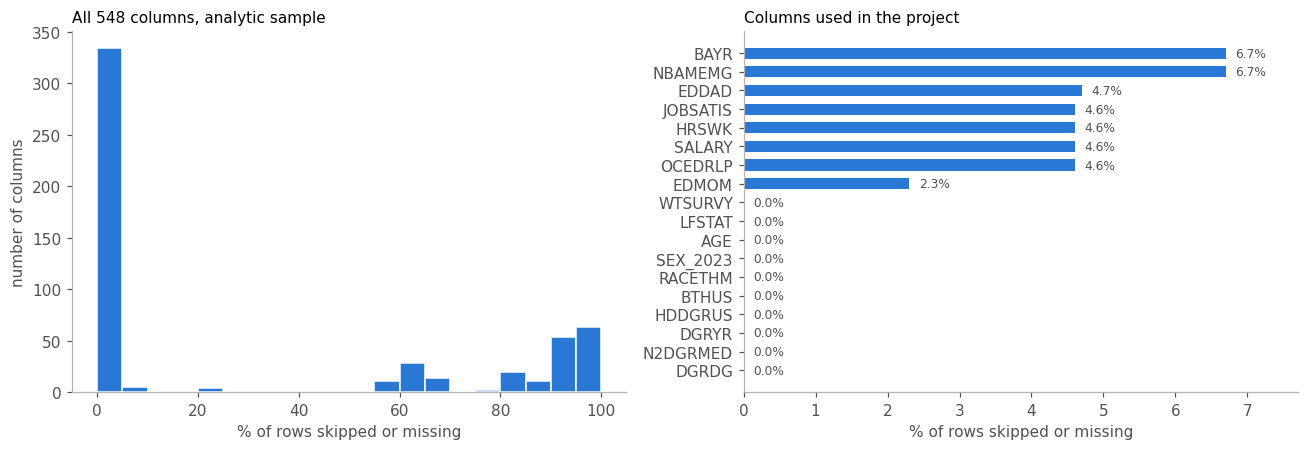

In [9]:
def missing_profile(frame, cols):
    rows = []
    for c in cols:
        x = frame[c]
        num = pd.to_numeric(x, errors="coerce")
        rows.append({
            "column": c,
            "% logical skip (L)": (x == "L").mean() * 100,
            "% reserved numeric": num.isin(NUMERIC_RESERVED.get(c, [])).mean() * 100,
            "% reserved category": x.isin(CAT_RESERVED.get(c, [])).mean() * 100,
            "% blank": x.isna().mean() * 100,
        })
    out = pd.DataFrame(rows).set_index("column").round(1)
    out["% total"] = out.sum(axis=1)
    return out

all_prof = missing_profile(s, s.columns)
print(f"Across all {s.shape[1]} columns in the analytic sample:")
print(f"  columns with no skip/missing values:     {(all_prof['% total'] == 0).sum()}")
print(f"  columns with >50% skip/missing:          {(all_prof['% total'] > 50).sum()}")
print(f"  columns with any true blanks:            {(all_prof['% blank'] > 0).sum()}")

keep_prof = missing_profile(s, KEEP)
display(keep_prof)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].hist(all_prof["% total"], bins=20, color=BLUE, edgecolor="white")
axes[0].set_xlabel("% of rows skipped or missing")
axes[0].set_ylabel("number of columns")
axes[0].set_title(f"All {s.shape[1]} columns, analytic sample", loc="left", fontsize=10)
kp = keep_prof["% total"].sort_values()
axes[1].barh(kp.index, kp.values, color=BLUE, height=0.6)
pad = max(kp.max(), 1) * 0.02
axes[1].set_xlim(0, max(kp.max(), 1) * 1.15)
for i, v in enumerate(kp.values):
    axes[1].text(v + pad, i, f"{v:.1f}%", va="center", fontsize=8, color=INK2)
axes[1].set_xlabel("% of rows skipped or missing")
axes[1].set_title("Columns used in the project", loc="left", fontsize=10)
plt.tight_layout(); plt.show()

**Is the missingness random or structural?** If skips in the target columns are only for people who are not working, they are *structural* (the question did not apply) and are not a data-quality problem: they carry information and are used directly when building the target. The cross-tabulations below check this.

In [10]:
lf = s.LFSTAT.map({"1": "Employed", "2": "Unemployed"})
print("OCEDRLP (job related to degree) skipped, by labor-force status:")
display(pd.crosstab(lf, s.OCEDRLP.eq("L"), margins=True).rename(columns={False: "answered", True: "skipped (L)"}))

hrs_raw = pd.to_numeric(s.HRSWK, errors="coerce")
print("HRSWK (hours) skipped, by labor-force status:")
display(pd.crosstab(lf, hrs_raw.eq(98) | s.HRSWK.eq("L"), margins=True).rename(columns={False: "answered", True: "skipped"}))

# Who has no first-bachelor's record (BAYR = 9998, NBAMEMG = 8)?
if "BAYR" in s.columns:
    ba_skip = pd.to_numeric(s.BAYR, errors="coerce").eq(9998)
    print("No first-bachelor's record, by highest degree:")
    display(pd.crosstab(s.DGRDG.map({"1": "Bachelor's", "2": "Master's"}), ba_skip, margins=True)
              .rename(columns={False: "BAYR recorded", True: "BAYR = 9998"}))
    if "NBAMEMG" in s.columns:
        print("Same rows as NBAMEMG = 8?", bool((ba_skip == s.NBAMEMG.eq("8")).all()))
    print("Outcome rate with / without a first-bachelor's record:",
          s.groupby(ba_skip).apply(lambda d: (d.LFSTAT.eq("1") & pd.to_numeric(d.HRSWK, errors="coerce").between(35, 97)
                                               & d.OCEDRLP.isin(["1", "2"])).mean()).round(3).to_dict())

# Section 6: missing rate against a recorded variable. A pattern is evidence against MCAR,
# but cannot by itself tell MAR from MNAR.
real_missing = [c for c in KEEP if VARS[c][1] in ("predictor", "fairness")
                and keep_prof.loc[c, "% total"] > 0]
print("Predictor/fairness columns with any skip or missing value:", real_missing or "none")

# does missingness in any candidate predictor differ by degree level?
for c in [c for c in KEEP if VARS[c][1] == "predictor" and keep_prof.loc[c, "% total"] > 0]:
    flag = (s[c].eq("L") | s[c].isna() | s[c].isin(CAT_RESERVED.get(c, []))
            | pd.to_numeric(s[c], errors="coerce").isin(NUMERIC_RESERVED.get(c, [])))
    print(f"{c}: % skipped/missing by degree ->",
          (flag.groupby(s.DGRDG.map({'1': "Bachelor's", '2': "Master's"})).mean() * 100).round(1).to_dict())

OCEDRLP (job related to degree) skipped, by labor-force status:


OCEDRLP,answered,skipped (L),All
LFSTAT,,,
Employed,1394,0,1394
Unemployed,0,67,67
All,1394,67,1461


HRSWK (hours) skipped, by labor-force status:


HRSWK,answered,skipped,All
LFSTAT,,,
Employed,1394,0,1394
Unemployed,0,67,67
All,1394,67,1461


No first-bachelor's record, by highest degree:


BAYR,BAYR recorded,BAYR = 9998,All
DGRDG,,,
Bachelor's,753,0,753
Master's,610,98,708
All,1363,98,1461


Same rows as NBAMEMG = 8? True
Outcome rate with / without a first-bachelor's record: {False: 0.847, True: 0.878}
Predictor/fairness columns with any skip or missing value: ['BAYR', 'NBAMEMG', 'EDMOM', 'EDDAD']
BAYR: % skipped/missing by degree -> {"Bachelor's": 0.0, "Master's": 13.8}
NBAMEMG: % skipped/missing by degree -> {"Bachelor's": 0.0, "Master's": 13.8}
EDMOM: % skipped/missing by degree -> {"Bachelor's": 3.2, "Master's": 1.4}
EDDAD: % skipped/missing by degree -> {"Bachelor's": 5.2, "Master's": 4.1}


**Decision on missing data.**

* Skips in `LFSTAT`, `HRSWK`, `OCEDRLP` are structural and are used to build the target (unemployed → negative class). No imputation.
* Skips in `SALARY` and `JOBSATIS` occur for people without a job; these are secondary outcomes analysed only among the employed, so the rows are simply not part of that analysis.
* Predictors kept for modelling have no true blanks in the analytic sample (see the table above). If a candidate predictor shows structural skips (for example first-bachelor's year for people whose only degree is that bachelor's), it is recoded to a meaningful value rather than imputed (see 3.4). If a predictor turns out to have real missingness, we follow Lecture 10: we do not drop rows by default (dropped rows may differ systematically), and impute **inside the modelling pipeline** in Milestone 3, fitted on training folds only, using `SimpleImputer` (median for numeric, most frequent for categorical) together with `MissingIndicator`, so that the model can learn whether "missing" is itself informative.

### 3.2 Response variable and class balance

* **y = 1**: employed **full time** (35+ hours/week) in a job **closely or somewhat related** to the highest degree.
* **y = 0**: unemployed, employed part time, or employed full time in an unrelated job.

The three negative outcomes are kept as a separate 4-level `outcome` column for reporting.

,n,unweighted %,weighted %
outcome,,,
"FT, degree-related",1240,84.9,78.4
"FT, not related",67,4.6,6.2
Part-time,87,6.0,6.2
Unemployed,67,4.6,9.2


Binary target: y=1: 1,240   y=0: 221   (minority class = 15.1% unweighted, 21.6% weighted)


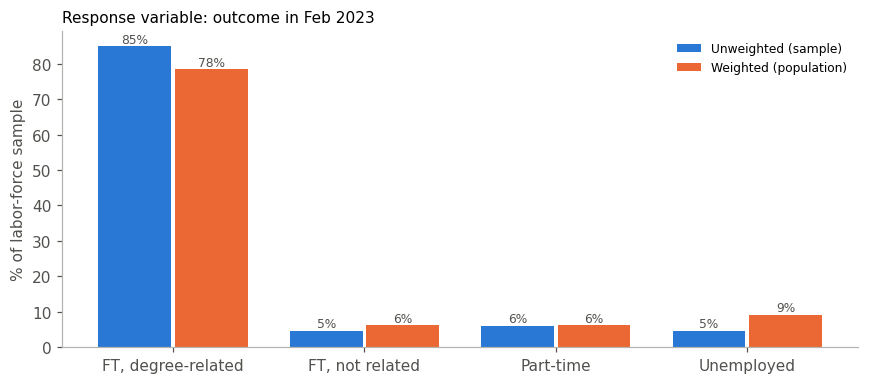

In [11]:
s["w"] = pd.to_numeric(s.WTSURVY)
hrs = hrs_raw.mask(hrs_raw.eq(98))
employed = s.LFSTAT.eq("1")
fulltime = employed & hrs.between(35, 97)
related = s.OCEDRLP.isin(["1", "2"])

s["y"] = (fulltime & related).astype(int)
s["outcome"] = np.select(
    [s.y.eq(1), ~employed, employed & ~fulltime],
    ["FT, degree-related", "Unemployed", "Part-time"],
    default="FT, not related",
)

order = ["FT, degree-related", "FT, not related", "Part-time", "Unemployed"]
balance = pd.DataFrame({
    "n": s.outcome.value_counts(),
    "unweighted %": s.outcome.value_counts(normalize=True) * 100,
    "weighted %": s.groupby("outcome").w.sum() / s.w.sum() * 100,
}).reindex(order).round(1)
display(balance)

print(f"Binary target: y=1: {s.y.sum():,}   y=0: {(s.y == 0).sum():,}   "
      f"(minority class = {(s.y == 0).mean():.1%} unweighted, "
      f"{1 - np.average(s.y, weights=s.w):.1%} weighted)")

fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(len(order)); bw = 0.38
b1 = ax.bar(x - bw/2 - 0.01, balance["unweighted %"], bw, color=BLUE, label="Unweighted (sample)")
b2 = ax.bar(x + bw/2 + 0.01, balance["weighted %"], bw, color=ORANGE, label="Weighted (population)")
for bars in (b1, b2):
    for b in bars:
        ax.text(b.get_x() + b.get_width()/2, b.get_height() + 1, f"{b.get_height():.0f}%",
                ha="center", fontsize=8, color=INK2)
ax.set_xticks(x, order); ax.set_ylabel("% of labor-force sample")
ax.set_title("Response variable: outcome in Feb 2023", loc="left", fontsize=10)
ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

**Class imbalance.** The negative class (the group we most want to identify, graduates *without* a degree-related full-time job) is only about 15% of the sample. Consequences for Milestone 3:

* accuracy is misleading (predicting "everyone succeeds" is about 85% accurate), so the main metrics will be **PR-AUC for the negative class**, ROC-AUC and balanced accuracy, compared with a prevalence baseline;
* use a stratified train/test split (`train_test_split(..., stratify=y, random_state=109)`) and `StratifiedKFold` cross-validation, as in Section 7;
* consider class weights; do not oversample before splitting.

### 3.3 Unusual values

We check values that are impossible or far from the rest: hours, salary, graduation timing, and the survey weights themselves.

Hours/week (employed, n=1394): min 3, median 40, max 90; <10 h: 18, >80 h: 3
Salary (employed, n=1394): min 0, median 100,000, max 976,934
   salary = 0: 7,  salary < $10,000: 16
   rows at the maximum value (976,934): 1
   largest 5 salaries: [976934, 827838, 827838, 827838, 827838]
   salary < $10,000 by full-time status: {False: {False: 79, True: 8}, True: {False: 1299, True: 8}}

Graduation year range: 2018-2022
Approx. age at graduation: min 16, median 22, max 60; <18: 3, <19: 38, >50: 17
   (age is measured in Feb 2023 and graduation only by year, so this is approximate to about +/-1 year)
First bachelor's year after highest-degree year (impossible): 1


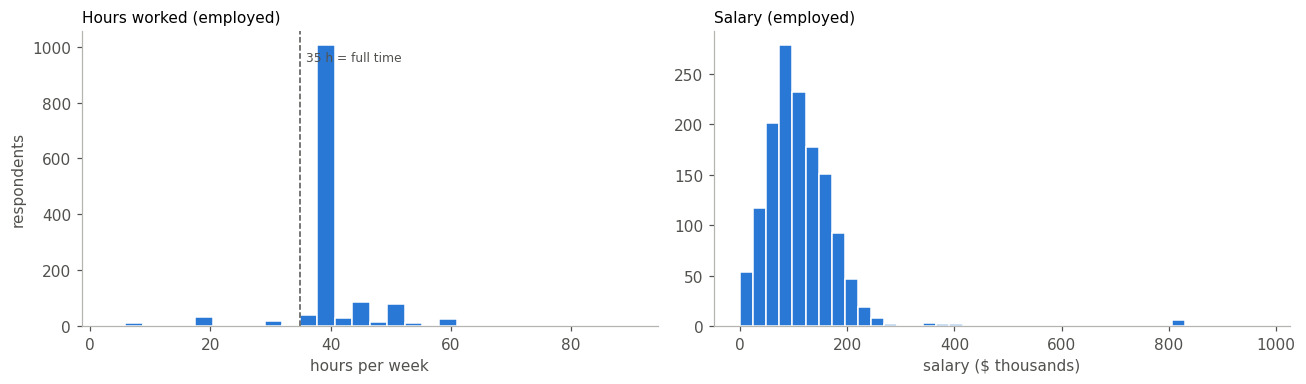

In [12]:
emp = s[employed]

# --- hours -------------------------------------------------------------------
h = hrs[employed]
print(f"Hours/week (employed, n={h.notna().sum()}): min {h.min():.0f}, median {h.median():.0f}, max {h.max():.0f}; "
      f"<10 h: {(h < 10).sum()}, >80 h: {(h > 80).sum()}")

# --- salary ------------------------------------------------------------------
sal = to_num("SALARY")[employed]
print(f"Salary (employed, n={sal.notna().sum()}): min {sal.min():,.0f}, median {sal.median():,.0f}, max {sal.max():,.0f}")
print(f"   salary = 0: {(sal == 0).sum()},  salary < $10,000: {(sal < 10_000).sum()}")
top = sal.max()
print(f"   rows at the maximum value ({top:,.0f}): {(sal == top).sum()}")
print("   largest 5 salaries:", sorted(sal.dropna().nlargest(5).astype(int).tolist(), reverse=True))
print("   salary < $10,000 by full-time status:",
      pd.crosstab(sal < 10_000, fulltime[employed]).to_dict())

# --- graduation timing ---------------------------------------------------------
gy = pd.to_numeric(s.DGRYR)
print(f"\nGraduation year range: {gy.min()}-{gy.max()}")
if "AGE" in s.columns:
    age_grad = to_num("AGE") - (SURVEY_YEAR - gy)
    print(f"Approx. age at graduation: min {age_grad.min():.0f}, median {age_grad.median():.0f}, max {age_grad.max():.0f}; "
          f"<18: {(age_grad < 18).sum()}, <19: {(age_grad < 19).sum()}, >50: {(age_grad > 50).sum()}")
    print("   (age is measured in Feb 2023 and graduation only by year, so this is approximate to about +/-1 year)")
if "BAYR" in s.columns:
    ba = to_num("BAYR")
    print(f"First bachelor's year after highest-degree year (impossible): {(ba > gy).sum()}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].hist(h.dropna(), bins=30, color=BLUE, edgecolor="white")
axes[0].axvline(35, color=INK2, ls="--", lw=1); axes[0].text(36, axes[0].get_ylim()[1]*0.9, "35 h = full time", fontsize=8, color=INK2)
axes[0].set_xlabel("hours per week"); axes[0].set_ylabel("respondents")
axes[0].set_title("Hours worked (employed)", loc="left", fontsize=10)
axes[1].hist(sal.dropna() / 1000, bins=40, color=BLUE, edgecolor="white")
axes[1].set_xlabel("salary ($ thousands)")
axes[1].set_title("Salary (employed)", loc="left", fontsize=10)
plt.tight_layout(); plt.show()

Weights: min 12.0, median 228.7, max 11,018.6  (max/min = 921x)
Population represented: 759,191
Top 5% of respondents carry 35% of the total weight
Kish effective sample size: 371 of 1461  (design effect ~ 3.9)


,n,share y=1
w,,
Q1 (smallest),293,0.870
Q2,292,0.894
Q3,292,0.846
Q4,292,0.818
Q5 (largest),292,0.815


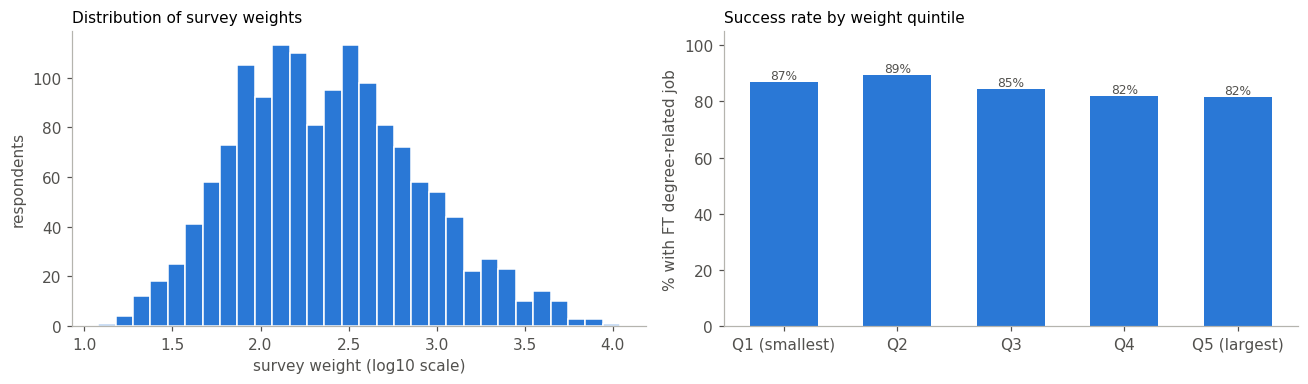

In [13]:
# --- survey weights ----------------------------------------------------------
w = s.w
n_eff = w.sum() ** 2 / (w ** 2).sum()
top5 = w.sort_values(ascending=False).head(int(np.ceil(len(w) * 0.05))).sum() / w.sum()
print(f"Weights: min {w.min():,.1f}, median {w.median():,.1f}, max {w.max():,.1f}  (max/min = {w.max() / w.min():,.0f}x)")
print(f"Population represented: {w.sum():,.0f}")
print(f"Top 5% of respondents carry {top5:.0%} of the total weight")
print(f"Kish effective sample size: {n_eff:.0f} of {len(w)}  (design effect ~ {len(w) / n_eff:.1f})")

# why is the weighted success rate lower than the unweighted one?
q = pd.qcut(w, 5, labels=["Q1 (smallest)", "Q2", "Q3", "Q4", "Q5 (largest)"])
by_q = s.groupby(q, observed=True).y.agg(["size", "mean"]).rename(columns={"size": "n", "mean": "share y=1"})
display(by_q.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].hist(np.log10(w), bins=30, color=BLUE, edgecolor="white")
axes[0].set_xlabel("survey weight (log10 scale)"); axes[0].set_ylabel("respondents")
axes[0].set_title("Distribution of survey weights", loc="left", fontsize=10)
axes[1].bar(by_q.index.astype(str), by_q["share y=1"] * 100, color=BLUE, width=0.6)
for i, v in enumerate(by_q["share y=1"] * 100):
    axes[1].text(i, v + 1, f"{v:.0f}%", ha="center", fontsize=8, color=INK2)
axes[1].set_ylabel("% with FT degree-related job"); axes[1].set_ylim(0, 105)
axes[1].set_title("Success rate by weight quintile", loc="left", fontsize=10)
plt.tight_layout(); plt.show()

**Decisions on unusual values.**

* **Hours**: very low or very high hours are plausible (part-time work, long hours in tech) and are kept. Hours are used only to define full-time status (≥ 35).
* **Salary**: 7 salaries of 0 and 16 below $10,000, mostly among part-time workers; these are real observations and are kept. At the top, several respondents share exactly $827,838 and one has $976,934: identical values like this are the public file's **top-coding** (very high salaries are replaced by a common value to protect respondents), so they are kept but flagged. Salary is a secondary outcome only; a salary model would use full-time workers and log salary, and treat top-coded values as "at least this high".
* **First bachelor's year**: 98 rows have `BAYR = 9998`, which is a logical-skip code, not a year (these were the "impossible" years above). The same 98 rows have `NBAMEMG = 8`, and **all 98 are master's holders** (13.8% of master's; none of the bachelor's holders). Their success rate (87.8%) is close to everyone else's (84.7%). They are recoded as "no first-bachelor's record" with an indicator column, not dropped.
* **Age at graduation**: approximate (age in 2023 minus years since graduation, so about ±1 year). The 3 values below 18 are corrected to 18. Older graduates (up to 60) are real (career changers, master's after work) and are kept.
* **One remaining inconsistency**: after removing the 9998 codes, 1 respondent has a first-bachelor's year later than the highest-degree year. The gap for that person is set to 0 rather than dropping the row.
* **Weights**: weights vary widely, and the effective sample size is about a quarter of the raw sample. Respondents with large weights have a lower success rate, which is why the weighted rate is lower than the unweighted rate. Weights are kept as-is (they are not errors). In Milestone 3 we will report weighted descriptive statistics, and compare models fit with and without `sample_weight`.

### 3.4 Recoding into analysis-ready features

* Codes are mapped to readable labels.
* **Field** is collapsed to two groups: the statistics / operations research / applied math group has too few people to split further.
* **Race/ethnicity**: the smallest groups (American Indian/Alaska Native, Native Hawaiian/Pacific Islander, multiple races) are combined into "Other/multiple". The raw counts are shown first so that this choice is visible.
* **Graduation year** is kept both as a number and as `years_since_grad` (time in the labor market before Feb 2023).
* Optional candidate predictors are derived only if they exist in the file. Parents' education codes are kept as categories; check the codebook for a "not applicable / don't know" code and group it separately rather than treating it as an education level.

In [14]:
print("Raw RACETHM codes in the sample:", s.RACETHM.value_counts().sort_index().to_dict())

clean = pd.DataFrame(index=s.index)
# response + reporting columns
clean["y"] = s.y
clean["outcome"] = s.outcome
clean["weight"] = s.w
# predictors (known at graduation)
clean["degree"] = s.DGRDG.map({"1": "Bachelor's", "2": "Master's"})
clean["field_group"] = s.N2DGRMED.map(FIELDS)
clean["grad_year"] = gy.astype(int)
clean["years_since_grad"] = SURVEY_YEAR - clean.grad_year
clean["us_school"] = s.HDDGRUS.map({"Y": 1, "N": 0})
if "AGE" in s.columns:
    age_grad = to_num("AGE") - clean.years_since_grad
    n_low = int((age_grad < 18).sum())
    # values below 18 come from the year-only approximation (and possibly public-file age
    # perturbation), not from real 16-year-old graduates: correct them to 18
    clean["age_at_grad"] = age_grad.clip(lower=18)
    print(f"age_at_grad: {n_low} values below 18 set to 18")
if "BAYR" in s.columns:
    ba_year = to_num("BAYR")                                  # 9998 -> NaN
    clean["no_ba_record"] = ba_year.isna().astype(int)        # missingness indicator (Lecture 10)
    gap = (gy - ba_year).clip(lower=0)
    # for someone whose highest degree IS the bachelor's, the gap is 0 by definition
    gap = gap.mask(gap.isna() & clean.degree.eq("Bachelor's"), 0)
    clean["years_ba_to_degree"] = gap                         # NaN left only where truly unknown
    print(f"years_ba_to_degree: {int(gap.isna().sum())} unknown (imputed inside the pipeline in Milestone 3)")
if "NBAMEMG" in s.columns:
    # major group of first bachelor's (labels: check codebook('NBAMEMG')); collapse small groups
    clean["ba_field_group"] = s.NBAMEMG.map({"1": "Computer/math", "5": "Engineering", "8": "No BA record"}) \
                                       .fillna("Other field").astype("category")
if {"EDMOM", "EDDAD"} <= set(s.columns):
    # highest education of either parent; 8 = not applicable (check codebook('EDMOM'))
    # codebook: 1-3 below bachelor's, 4 bachelor's, 5-7 master's/professional/doctorate, 8 not applicable
    ed = pd.DataFrame({c: pd.to_numeric(s[c]).where(lambda v: v != 8) for c in ["EDMOM", "EDDAD"]}).max(axis=1)
    clean["parent_ed"] = pd.cut(ed, [0, 3, 4, 7], labels=["Below bachelor's", "Bachelor's", "Graduate"]) \
                           .cat.add_categories("Not applicable").fillna("Not applicable")
# fairness / subgroup columns (not default model features)
clean["sex"] = s.SEX_2023.map({"M": "Male", "F": "Female"})
clean["race"] = s.RACETHM.map({"1": "Asian", "3": "Black", "4": "Hispanic", "5": "White"}).fillna("Other/multiple")
clean["born_us"] = s.BTHUS.map({"Y": "US-born", "N": "Foreign-born"})
# secondary outcomes (post-outcome, never features for y)
clean["salary"] = to_num("SALARY")
clean["very_satisfied"] = s.JOBSATIS.map({"1": 1, "2": 0, "3": 0, "4": 0})   # NaN if not employed

for c in ["degree", "field_group", "sex", "race", "born_us", "outcome"]:
    clean[c] = clean[c].astype("category")

# sanity check: every mapping produced a value
unmapped = clean[["degree", "field_group", "us_school", "sex", "born_us"]].isna().sum()
print("Unmapped values after recoding (should all be 0):", unmapped.to_dict())
print("\nCounts after collapsing small groups:")
for c in ["field_group", "race", "ba_field_group", "parent_ed"]:
    if c in clean.columns:
        print(f"  {c}:", clean[c].value_counts().to_dict())

Raw RACETHM codes in the sample: {'1': 530, '3': 121, '4': 206, '5': 554, '6': 2, '7': 48}
age_at_grad: 3 values below 18 set to 18
years_ba_to_degree: 98 unknown (imputed inside the pipeline in Milestone 3)
Unmapped values after recoding (should all be 0): {'degree': 0, 'field_group': 0, 'us_school': 0, 'sex': 0, 'born_us': 0}

Counts after collapsing small groups:
  field_group: {'CS': 1285, 'Stats/OR/Applied math': 176}
  race: {'White': 554, 'Asian': 530, 'Hispanic': 206, 'Black': 121, 'Other/multiple': 50}
  ba_field_group: {'Computer/math': 1015, 'Other field': 207, 'Engineering': 141, 'No BA record': 98}
  parent_ed: {'Graduate': 566, "Bachelor's": 452, "Below bachelor's": 416, 'Not applicable': 27}


### 3.5 Information leakage

A feature is allowed only if it would be known **at graduation**, before the outcome happens. Anything describing the February 2023 job, or measured as a consequence of it, is excluded. The table lists every column we considered and the decision.

In [15]:
LEAKAGE = [
    # column, decision, reason
    ("DGRDG / N2DGRMED / DGRYR / HDDGRUS", "feature", "degree level, field, year and school country are fixed at graduation"),
    ("BAYR, NBAMEMG, EDMOM, EDDAD, AGE",   "feature (if present)", "determined before or at graduation"),
    ("LFSTAT, HRSWK, OCEDRLP",             "excluded", "they define the target"),
    ("SALARY, JOBSATIS",                   "excluded", "describe the job that is the outcome (secondary outcomes only)"),
    ("Occupation codes (e.g. N2OCPRMG)",   "excluded", "occupation of the Feb-2023 job: a direct consequence of the outcome"),
    ("Employer size / sector (e.g. EMSIZE, EMSECDT)", "excluded", "describe the employer, known only once employed"),
    ("Reason for working outside field (e.g. NRREA)", "excluded", "asked only of people already in the negative class"),
    ("Region of residence / employer in 2023", "excluded", "measured after graduation; people may move for a job"),
    ("SEX_2023, RACETHM, BTHUS",           "fairness only", "protected characteristics: used to evaluate errors by group"),
    ("WTSURVY",                            "weight", "survey design, not a feature"),
]
display(pd.DataFrame(LEAKAGE, columns=["column(s)", "decision", "reason"]))

# which of the excluded post-outcome columns actually exist in this file?
post_outcome_examples = ["N2OCPRMG", "NOCPRMG", "EMSIZE", "EMSECDT", "NRREA", "EMRG"]
print("Post-outcome columns present in the raw file (excluded):",
      [c for c in post_outcome_examples if c in df.columns])

,column(s),decision,reason
0,DGRDG / N2DGRMED / DGRYR / HDDGRUS,feature,"degree level, field, year and school country a..."
1,"BAYR, NBAMEMG, EDMOM, EDDAD, AGE",feature (if present),determined before or at graduation
2,"LFSTAT, HRSWK, OCEDRLP",excluded,they define the target
3,"SALARY, JOBSATIS",excluded,describe the job that is the outcome (secondar...
4,Occupation codes (e.g. N2OCPRMG),excluded,occupation of the Feb-2023 job: a direct conse...
5,"Employer size / sector (e.g. EMSIZE, EMSECDT)",excluded,"describe the employer, known only once employed"
6,Reason for working outside field (e.g. NRREA),excluded,asked only of people already in the negative c...
7,Region of residence / employer in 2023,excluded,measured after graduation; people may move for...
8,"SEX_2023, RACETHM, BTHUS",fairness only,protected characteristics: used to evaluate er...
9,WTSURVY,weight,"survey design, not a feature"


Post-outcome columns present in the raw file (excluded): ['N2OCPRMG', 'EMSIZE', 'EMSECDT', 'NRREA', 'EMRG']


### 3.6 Scale of the features

Most predictors are categorical and will be one-hot encoded (0/1). The numeric predictors are on different scales, so they will be standardized for regularized logistic regression and k-NN (tree models do not need it).

Following Sections 4 and 5, every step that is fitted to data (the scaler, the encoder, any imputer) goes **inside a `Pipeline`** with a `ColumnTransformer` (`StandardScaler` for numeric columns, `OneHotEncoder(drop="first", handle_unknown="ignore")` for categorical ones), so it is refitted in every cross-validation fold. `pd.get_dummies` below is used only to count how many columns the encoding produces.

Parents' education is **ordinal**. We one-hot encode it, which makes no assumption about equal spacing between levels (Section 3).

**Events per feature.** With the raw 8-level codes for first-bachelor's field and each parent's education, the design matrix had 27 columns, only about 8 minority-class cases per column. Collapsing them (3.4) keeps the information that matters and roughly halves the number of columns.

In [16]:
# grad_year and years_since_grad are the same information (perfectly collinear): only grad_year is a feature
FEATURES = [c for c in ["degree", "field_group", "grad_year", "us_school",
                        "age_at_grad", "years_ba_to_degree", "no_ba_record", "ba_field_group", "parent_ed"]
            if c in clean.columns]
num_feats = [c for c in FEATURES if pd.api.types.is_numeric_dtype(clean[c])]
cat_feats = [c for c in FEATURES if c not in num_feats]

display(clean[num_feats].agg(["min", "max", "mean", "std"]).T.round(2))
# get_dummies drops NaN, so fill only for this column count (the pipeline imputes properly later)
print("Categorical features and number of levels:", {c: clean[c].nunique() for c in cat_feats})
X_preview = pd.get_dummies(clean[FEATURES].fillna({c: 0 for c in num_feats}), drop_first=True)
print(f"Design matrix after one-hot encoding: {X_preview.shape[0]} rows x {X_preview.shape[1]} columns")
print(f"Events per feature (minority class / columns): {(clean.y == 0).sum() / X_preview.shape[1]:.0f}")

,min,max,mean,std
grad_year,2018.0,2022.0,2019.48,1.26
us_school,0.0,1.0,0.97,0.17
age_at_grad,18.0,60.0,24.28,6.60
years_ba_to_degree,0.0,35.0,2.65,4.55
no_ba_record,0.0,1.0,0.07,0.25


Categorical features and number of levels: {'degree': 2, 'field_group': 2, 'ba_field_group': 4, 'parent_ed': 4}
Design matrix after one-hot encoding: 1461 rows x 13 columns
Events per feature (minority class / columns): 17


## 4. The cleaned table

One row = one graduate in the analytic sample. Columns: the response (`y`), the 4-level `outcome` for reporting, the survey `weight`, the features known at graduation, the fairness columns and the secondary outcomes.

In [17]:
print(f"Cleaned table: {clean.shape[0]:,} rows x {clean.shape[1]} columns")
print(f"Model features: {len(FEATURES)}  ->  {FEATURES}")
display(pd.DataFrame({"dtype": clean.dtypes.astype(str),
                      "% missing": (clean.isna().mean() * 100).round(1),
                      "example": clean.iloc[0].astype(str)}))
display(clean.head())

out_path = DATA_DIR / "nscg_clean.csv"
clean.to_csv(out_path, index_label="row_id")
print(f"Saved {out_path} ({out_path.stat().st_size / 1e6:.2f} MB)")

Cleaned table: 1,461 rows x 18 columns
Model features: 9  ->  ['degree', 'field_group', 'grad_year', 'us_school', 'age_at_grad', 'years_ba_to_degree', 'no_ba_record', 'ba_field_group', 'parent_ed']


,dtype,% missing,example
y,int64,0.0,1
outcome,category,0.0,"FT, degree-related"
weight,float64,0.0,70.4637
degree,category,0.0,Master's
field_group,category,0.0,CS
grad_year,int64,0.0,2020
years_since_grad,int64,0.0,3
us_school,int64,0.0,1
age_at_grad,int64,0.0,30
no_ba_record,int64,0.0,0


,y,outcome,weight,degree,field_group,grad_year,years_since_grad,us_school,age_at_grad,no_ba_record,years_ba_to_degree,ba_field_group,parent_ed,sex,race,born_us,salary,very_satisfied
151,1,"FT, degree-related",70.4637,Master's,CS,2020,3,1,30,0,7.0,Engineering,Below bachelor's,Female,Hispanic,US-born,92000.0,1.0
721,1,"FT, degree-related",2716.2845,Master's,CS,2018,5,1,24,0,4.0,Other field,Graduate,Male,Asian,Foreign-born,190550.0,0.0
1075,1,"FT, degree-related",24.3938,Master's,CS,2018,5,1,38,0,17.0,Other field,Graduate,Male,White,US-born,235000.0,0.0
1170,1,"FT, degree-related",159.9455,Master's,CS,2020,3,1,28,0,8.0,Computer/math,Graduate,Male,White,US-born,200000.0,0.0
1269,1,"FT, degree-related",356.0695,Master's,Stats/OR/Applied math,2018,5,1,29,0,9.0,Computer/math,Below bachelor's,Male,Hispanic,Foreign-born,101000.0,1.0


Saved nscg_data\nscg_clean.csv (0.19 MB)


`salary` and `very_satisfied` are missing by design for people who are not employed; they are used only in the secondary analyses of employed graduates.

## 5. What we learned from the data

Numbers below are printed by the cells above; the summary repeats the key ones.

In [18]:
summary = {
    "raw file (rows x cols)": f"{df.shape[0]:,} x {df.shape[1]}",
    "analytic sample": f"{len(clean):,}",
    "cleaned table (rows x cols)": f"{clean.shape[0]:,} x {clean.shape[1]}",
    "y=1 / y=0": f"{clean.y.sum():,} / {(clean.y == 0).sum():,}",
    "weighted share y=1": f"{np.average(clean.y, weights=clean.weight):.1%}",
    "Kish effective n": f"{n_eff:.0f}",
    "Stats/OR/Applied math n": f"{(clean.field_group == 'Stats/OR/Applied math').sum()}",
    "non-US school n": f"{(clean.us_school == 0).sum()}",
    "FT, not related n": f"{(clean.outcome == 'FT, not related').sum()}",
    "model features (one-hot columns)": f"{len(FEATURES)} ({X_preview.shape[1]})",
}
pd.Series(summary, name="value").to_frame()

,value
raw file (rows x cols),"94,606 x 548"
analytic sample,"1,461"
cleaned table (rows x cols),"1,461 x 18"
y=1 / y=0,"1,240 / 221"
weighted share y=1,78.4%
Kish effective n,371
Stats/OR/Applied math n,176
non-US school n,43
"FT, not related n",67
model features (one-hot columns),9 (13)


1. **The original target can be built from the data.** Labor-force status, hours and degree-relatedness give a clean binary response; skips in these columns are structural, not missing data.
2. **The negative class is small** (221 of 1,461, about 15%), so accuracy is not a useful metric; we will use PR-AUC for the negative class, ROC-AUC and balanced accuracy, with stratified splits.
3. **Survey weights matter.** The weighted success rate (≈78%) is lower than the unweighted one (≈85%) because heavily weighted respondents do worse, and the effective sample size is only ≈370. The data supports a modest number of features, not a large model.
4. **Some groups are too small to analyse on their own**: statistics/OR/applied math (n = 176), non-US school (n = 43), small race groups (n = 50 combined), the 2022 cohort (n = 120). We collapsed field and race categories and will report wide intervals for small groups.
5. **Geography and labor-market conditions cannot be used as planned.** The only geography in the file describes where people live/work in 2023 (leakage), and labor-market conditions vary only by graduation year in this cross-section. Graduation cohort (including the 2020–21 COVID years) is the labor-market proxy; BLS/JOLTS data is used for context only.
6. **Five more pre-graduation variables exist** (year and field of first bachelor's, each parent's education, age), but some carry skip codes (`BAYR = 9998` for 98 master's holders with no first-bachelor's record) and many small levels; with 221 negatives and an effective n of about 370, we collapse them to keep about 13 model columns. The project is framed as "how predictable is this outcome from graduation-time information", not as building a highly accurate predictor.
7. **Secondary questions are narrowed**: only 67 people work full time outside their field, too few to model the reasons; satisfaction becomes descriptive.

## 6. Revised project question

**Primary question.** Among 2018–2022 bachelor's and master's graduates in computer science, statistics, operations research and applied mathematics who were in the US labor force in February 2023 (NSCG 2023, n = 1,461), how well can information available at graduation (degree level, field group, graduation cohort, school location and other pre-graduation characteristics) predict holding a full-time job that is closely or somewhat related to the degree, and which of these factors are most strongly associated with it?

**How we will know it was answered.**

* On a fixed, stratified 20% holdout set, the best model is compared with a prevalence baseline using **PR-AUC for the negative class** (baseline ≈ 0.15), ROC-AUC (baseline 0.5) and balanced accuracy, with bootstrap confidence intervals. "Answered" means we can state whether, and by how much, graduation-time information beats the baseline, including the possibility that it does not.
* The predictors' associations are reported as odds ratios from regularized logistic regression and as permutation importance, with uncertainty.

**Secondary (narrowed).**

* Bachelor's vs master's: difference in the weighted rate of the outcome, with a confidence interval.
* Salary among full-time employed graduates (log salary regression).
* Model error rates (false negatives/positives) by sex, collapsed race/ethnicity and US-born vs foreign-born.

**Changes from the original proposal:** geographic and labor-market predictors removed (leakage / no variation in a cross-section); field collapsed to two groups; reasons for working outside the field and very high satisfaction become descriptive only; an explicit success criterion was added.

### Staff caveats (approved project list, project #2, status: Approved)

| Staff caveat | How we address it |
|---|---|
| The main question is whether graduates hold full-time, degree-related jobs | This is the primary question and the binary response `y` (3.2) |
| Salary and job-satisfaction models are optional if time allows | Salary is a secondary analysis only if time allows; satisfaction is descriptive only |
| Only 221 graduates without full-time, degree-related jobs, so small-subgroup estimates may be uncertain | Small groups are collapsed (3.4), groups with few negatives are flagged, and results are reported with confidence intervals; metrics focus on the minority class (3.2) |
| Account for survey weights when generalizing to the graduate population | Population statements use `WTSURVY` (weighted rates, Kish effective sample size, 3.3); models are compared with and without `sample_weight` |

## 7. Use of generative AI and outside resources

* _Generative AI:_ _Claude_ was used to draft and debug parts of the data-loading and cleaning code and to suggest wording. All code was run, checked and edited by the group, who take responsibility for it.
* _Data:_ National Center for Science and Engineering Statistics. National Survey of College Graduates, 2023 Public Use File. <https://ncses.nsf.gov/explore-data/microdata/national-survey-college-graduates>